In [1]:
############################################################
# 1. CONFIGURATION
############################################################

CONFIG = {

    # Dataset
    "DATA_DIR": "/kaggle/input/notebooks/ssuhaass/01-data-preprocessing-ipynb/processed_data",

    # Training
    "BATCH_SIZE": 128,
    "EPOCHS": 100,
    "LEARNING_RATE": 1e-3,
    "WEIGHT_DECAY": 1e-4,
    "PATIENCE": 15,

    # Model
    "PATCH_SIZE": 9,
    "PCA_COMPONENTS": 30,
    "HIDDEN_SIZE": 128,
    "NUM_LAYERS": 2,
    "DROPOUT": 0.3,
    "NUM_CLASSES": 9,

    # Misc
    "SEED": 42,
    "NUM_WORKERS": 2,
    "SAVE_DIR": "./outputs",

    # AMP
    "USE_AMP": True
}

In [2]:
############################################################
# 2. IMPORTS
############################################################

import os
import random
import warnings
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

warnings.filterwarnings("ignore")

In [3]:
############################################################
# 3. REPRODUCIBILITY
############################################################

def seed_everything(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False

seed_everything(CONFIG["SEED"])

In [4]:
############################################################
# 4. DEVICE
############################################################

DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else

    "cpu"

)

print(f"Using Device : {DEVICE}")

Using Device : cuda


In [5]:
############################################################
# 5. OUTPUT DIRECTORY
############################################################

os.makedirs(

    CONFIG["SAVE_DIR"],

    exist_ok=True

)

In [6]:
############################################################
# 6. LOAD DATA
############################################################

train_data = np.load(

    os.path.join(

        CONFIG["DATA_DIR"],

        "train.npz"

    )

)

val_data = np.load(

    os.path.join(

        CONFIG["DATA_DIR"],

        "validation.npz"

    )

)

test_data = np.load(

    os.path.join(

        CONFIG["DATA_DIR"],

        "test.npz"

    )

)

X_train = train_data["X"]

y_train = train_data["y"]

X_val = val_data["X"]

y_val = val_data["y"]

X_test = test_data["X"]

y_test = test_data["y"]

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(2138, 9, 9, 30)
(2138, 9, 9, 30)
(38500, 9, 9, 30)


In [7]:
############################################################
# 7. DATASET
############################################################

class HSIDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(

            X,

            dtype=torch.float32

        )

        self.y = torch.tensor(

            y,

            dtype=torch.long

        )

    def __len__(self):

        return len(self.X)

    def __getitem__(self, idx):

        return self.X[idx], self.y[idx]

In [8]:
############################################################
# 8. DATALOADER
############################################################

train_dataset = HSIDataset(

    X_train,

    y_train

)

val_dataset = HSIDataset(

    X_val,

    y_val

)

test_dataset = HSIDataset(

    X_test,

    y_test

)

train_loader = DataLoader(

    train_dataset,

    batch_size=CONFIG["BATCH_SIZE"],

    shuffle=True,

    num_workers=CONFIG["NUM_WORKERS"],

    pin_memory=True

)

val_loader = DataLoader(

    val_dataset,

    batch_size=CONFIG["BATCH_SIZE"],

    shuffle=False,

    num_workers=CONFIG["NUM_WORKERS"],

    pin_memory=True

)

test_loader = DataLoader(

    test_dataset,

    batch_size=CONFIG["BATCH_SIZE"],

    shuffle=False,

    num_workers=CONFIG["NUM_WORKERS"],

    pin_memory=True

)

print("Train batches :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches :", len(test_loader))

Train batches : 17
Validation batches : 17
Test batches : 301


In [9]:
############################################################
# 9. DATASET STATISTICS
############################################################

print("="*60)

print("Training Samples :", len(train_dataset))

print("Validation Samples :", len(val_dataset))

print("Testing Samples :", len(test_dataset))

print("Patch Shape :", X_train.shape[1:])

print("Number of Classes :", CONFIG["NUM_CLASSES"])

print("="*60)

Training Samples : 2138
Validation Samples : 2138
Testing Samples : 38500
Patch Shape : (9, 9, 30)
Number of Classes : 9


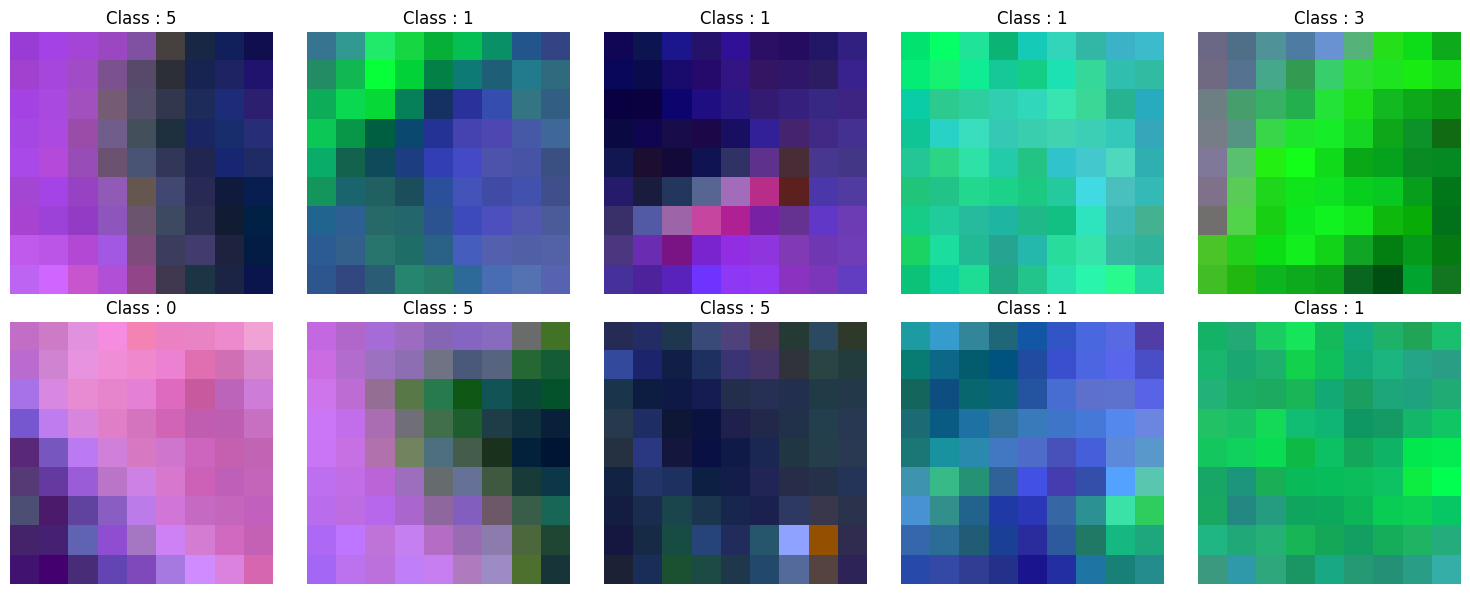

In [10]:
############################################################
# 10. VISUALIZE SAMPLE PATCHES
############################################################

fig, axes = plt.subplots(2, 5, figsize=(15,6))

axes = axes.flatten()

for i in range(10):

    patch = X_train[i]

    rgb = patch[:, :, :3]

    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)

    axes[i].imshow(rgb)

    axes[i].set_title(f"Class : {y_train[i]}")

    axes[i].axis("off")

plt.tight_layout()

plt.show()

In [11]:
############################################################
# 11. RESIDUAL 3D CNN BLOCK
############################################################

class Residual3DBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv1 = nn.Conv3d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm3d(out_channels)

        self.conv2 = nn.Conv3d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm3d(out_channels)

        self.relu = nn.GELU()

        if in_channels != out_channels:

            self.shortcut = nn.Sequential(

                nn.Conv3d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    bias=False
                ),

                nn.BatchNorm3d(out_channels)

            )

        else:

            self.shortcut = nn.Identity()

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out += identity

        out = self.relu(out)

        return out

In [12]:
############################################################
# 12. SQUEEZE AND EXCITATION BLOCK
############################################################

class SEBlock(nn.Module):

    def __init__(self, channels, reduction=8):

        super().__init__()

        self.pool = nn.AdaptiveAvgPool3d(1)

        self.fc = nn.Sequential(

            nn.Linear(channels, channels // reduction),

            nn.ReLU(),

            nn.Linear(channels // reduction, channels),

            nn.Sigmoid()

        )

    def forward(self, x):

        b, c, d, h, w = x.shape

        y = self.pool(x).view(b, c)

        y = self.fc(y).view(b, c, 1, 1, 1)

        return x * y

In [13]:
############################################################
# 13. CNN FEATURE EXTRACTOR
############################################################

class CNNBlock(nn.Module):

    def __init__(self):
        super().__init__()

        self.block1 = Residual3DBlock(1, 16)

        self.block2 = Residual3DBlock(16, 32)

        self.se = SEBlock(32)

        self.pool = nn.MaxPool3d(
            kernel_size=(1, 2, 2)
        )

        # Fix spatial dimensions to 1×1
        self.global_pool = nn.AdaptiveAvgPool3d(
            (CONFIG["PCA_COMPONENTS"], 1, 1)
        )

        self.dropout = nn.Dropout3d(0.25)

    def forward(self, x):

        x = self.block1(x)

        x = self.pool(x)

        x = self.block2(x)

        x = self.se(x)

        x = self.pool(x)

        x = self.global_pool(x)

        x = self.dropout(x)

        return x

In [14]:
############################################################
# 14. BiLSTM
############################################################

class BiLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        self.lstm = nn.LSTM(

            input_size=32,      # fixed

            hidden_size=CONFIG["HIDDEN_SIZE"],

            num_layers=CONFIG["NUM_LAYERS"],

            batch_first=True,

            dropout=CONFIG["DROPOUT"],

            bidirectional=True

        )

    def forward(self, x):

        output, _ = self.lstm(x)

        return output

In [15]:
############################################################
# 15. TEMPORAL ATTENTION
############################################################

class Attention(nn.Module):

    def __init__(self,hidden_size):

        super().__init__()

        self.attention = nn.Sequential(

            nn.Linear(hidden_size*2,hidden_size),

            nn.Tanh(),

            nn.Linear(hidden_size,1)

        )

    def forward(self,x):

        weights = self.attention(x)

        weights = torch.softmax(weights,dim=1)

        output = torch.sum(weights*x,dim=1)

        return output

In [16]:
############################################################
# 16. COMPLETE MODEL
############################################################

class CNN_BiLSTM_Attention(nn.Module):

    def __init__(self):

        super().__init__()

        self.cnn = CNNBlock()

        self.bilstm = BiLSTM()

        self.attention = Attention(CONFIG["HIDDEN_SIZE"])

        self.dropout = nn.Dropout(CONFIG["DROPOUT"])

        self.classifier = nn.Sequential(

            nn.Linear(
                CONFIG["HIDDEN_SIZE"] * 2,
                128
            ),

            nn.GELU(),

            nn.Dropout(CONFIG["DROPOUT"]),

            nn.Linear(
                128,
                CONFIG["NUM_CLASSES"]
            )

        )

    def forward(self, x):

        ####################################################
        # Input : (B,H,W,C)
        ####################################################

        x = x.permute(0, 3, 1, 2)

        ####################################################
        # (B,1,C,H,W)
        ####################################################

        x = x.unsqueeze(1)

        ####################################################
        # CNN
        ####################################################

        x = self.cnn(x)

        ####################################################
        # CNN Output:
        # (B,32,PCA_COMPONENTS,1,1)
        ####################################################

        b, c, d, h, w = x.shape

        ####################################################
        # (B,d,c)
        ####################################################

        x = x.squeeze(-1).squeeze(-1)

        x = x.permute(0, 2, 1)

        ####################################################
        # BiLSTM
        ####################################################

        x = self.bilstm(x)

        ####################################################
        # Attention
        ####################################################

        x = self.attention(x)

        ####################################################
        # Dropout
        ####################################################

        x = self.dropout(x)

        ####################################################
        # Classification
        ####################################################

        x = self.classifier(x)

        return x

In [17]:
############################################################
# 17. CREATE MODEL
############################################################

model = CNN_BiLSTM_Attention().to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("="*60)
print(model)
print("="*60)
print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")
print("="*60)

CNN_BiLSTM_Attention(
  (cnn): CNNBlock(
    (block1): Residual3DBlock(
      (conv1): Conv3d(1, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (bn1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (bn2): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): GELU(approximate='none')
      (shortcut): Sequential(
        (0): Conv3d(1, 16, kernel_size=(1, 1, 1), stride=(1, 1, 1), bias=False)
        (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (block2): Residual3DBlock(
      (conv1): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (bn1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv3d(32, 32, kernel_size=(3, 3, 3), stri

In [18]:
############################################################
# 18. LOSS, OPTIMIZER & SCHEDULER
############################################################

criterion = nn.CrossEntropyLoss()

optimizer = AdamW(

    model.parameters(),

    lr=CONFIG["LEARNING_RATE"],

    weight_decay=CONFIG["WEIGHT_DECAY"]

)

scheduler = CosineAnnealingLR(

    optimizer,

    T_max=CONFIG["EPOCHS"],

    eta_min=1e-6

)

print("Loss      :", criterion)
print("Optimizer :", optimizer.__class__.__name__)
print("Scheduler :", scheduler.__class__.__name__)

Loss      : CrossEntropyLoss()
Optimizer : AdamW
Scheduler : CosineAnnealingLR


In [19]:
############################################################
# 19. AUTOMATIC MIXED PRECISION
############################################################

USE_AMP = CONFIG["USE_AMP"] and DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("AMP Enabled :", USE_AMP)

AMP Enabled : True


In [20]:
############################################################
# 20. EARLY STOPPING
############################################################

class EarlyStopping:

    def __init__(self,
                 patience=15,
                 delta=0.0):

        self.patience = patience

        self.delta = delta

        self.best_score = None

        self.counter = 0

        self.early_stop = False

    def __call__(self, score):

        if self.best_score is None:

            self.best_score = score

        elif score < self.best_score + self.delta:

            self.counter += 1

            print(
                f"EarlyStopping Counter : "
                f"{self.counter}/{self.patience}"
            )

            if self.counter >= self.patience:

                self.early_stop = True

        else:

            self.best_score = score

            self.counter = 0

early_stopping = EarlyStopping(
    patience=CONFIG["PATIENCE"]
)

In [21]:
############################################################
# 21. TRAINING HISTORY
############################################################

history = {

    "train_loss": [],

    "val_loss": [],

    "train_acc": [],

    "val_acc": [],

    "lr": []

}

In [22]:
############################################################
# 22. TRAIN FUNCTION
############################################################

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0.0

    predictions = []

    labels = []

    progress = tqdm(

        loader,

        leave=False,

        desc="Training"

    )

    for x, y in progress:

        x = x.to(DEVICE, non_blocking=True)

        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(

            device_type=DEVICE.type,

            enabled=USE_AMP

        ):

            outputs = model(x)

            loss = criterion(outputs, y)

        scaler.scale(loss).backward()

        torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            max_norm=1.0

        )

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        preds = outputs.argmax(dim=1)

        predictions.extend(
            preds.detach().cpu().numpy()
        )

        labels.extend(
            y.detach().cpu().numpy()
        )

        progress.set_postfix(

            loss=f"{loss.item():.4f}"

        )

    epoch_loss = running_loss / len(loader)

    epoch_acc = accuracy_score(

        labels,

        predictions

    ) * 100

    return epoch_loss, epoch_acc

In [23]:
############################################################
# 23. VALIDATION FUNCTION
############################################################

@torch.no_grad()

def validate(model, loader):

    model.eval()

    running_loss = 0.0

    predictions = []

    labels = []

    progress = tqdm(

        loader,

        leave=False,

        desc="Validation"

    )

    for x, y in progress:

        x = x.to(DEVICE, non_blocking=True)

        y = y.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(

            device_type=DEVICE.type,

            enabled=USE_AMP

        ):

            outputs = model(x)

            loss = criterion(outputs, y)

        running_loss += loss.item()

        preds = outputs.argmax(dim=1)

        predictions.extend(

            preds.cpu().numpy()

        )

        labels.extend(

            y.cpu().numpy()

        )

    epoch_loss = running_loss / len(loader)

    epoch_acc = accuracy_score(

        labels,

        predictions

    ) * 100

    return epoch_loss, epoch_acc

In [24]:
############################################################
# 24. TRAINING VARIABLES
############################################################

best_val_acc = 0.0

start_time = time.time()

checkpoint_path = os.path.join(

    CONFIG["SAVE_DIR"],

    "best_checkpoint.pth"

)

In [25]:
############################################################
# 25. TRAINING LOOP
############################################################

print("="*70)
print("Training Started")
print("="*70)

for epoch in range(CONFIG["EPOCHS"]):

    print("\n" + "="*70)
    print(f"Epoch [{epoch+1}/{CONFIG['EPOCHS']}]")
    print("="*70)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc = validate(
        model,
        val_loader
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["lr"].append(
        optimizer.param_groups[0]["lr"]
    )

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Val Acc    : {val_acc:.2f}%")

    print(f"Learning Rate : {optimizer.param_groups[0]['lr']:.8f}")

    ####################################################
    # Save Best Model
    ####################################################

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        checkpoint = {

            "epoch": epoch,

            "model_state_dict": model.state_dict(),

            "optimizer_state_dict": optimizer.state_dict(),

            "scheduler_state_dict": scheduler.state_dict(),

            "best_val_acc": best_val_acc

        }

        torch.save(

            checkpoint,

            checkpoint_path

        )

        print("Best model saved.")

    early_stopping(val_acc)

    if early_stopping.early_stop:

        print("\nEarly stopping activated.")

        break

print("\nTraining Completed.")

Training Started

Epoch [1/100]


Training:   0%|          | 0/17 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x783e24552de0>
<function _MultiProcessingDataLoaderIter.__del__ at 0x783e24552de0>Traceback (most recent call last):

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
self._shutdown_workers()    self._shutdown_workers()

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
        if w.is_alive():if w.is_alive():



Validation:   0%|          | 0/17 [00:00<?, ?it/s]

              ^^^^^^^^^^^^^^^^^^^^^^^
^  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a child process'    assert self._parent_pid == os.getpid(), 'can only test a child process'

                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
^AssertionError^: can only test a child process^

AssertionError: can only test a child process


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x783e24552de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x783e24552de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Train Loss : 0.0218
Train Acc  : 99.72%
Val Loss   : 0.3298
Val Acc    : 97.71%
Learning Rate : 0.00033130
EarlyStopping Counter : 14/15

Epoch [62/100]


Training:   0%|          | 0/17 [00:00<?, ?it/s]

Validation:   0%|          | 0/17 [00:00<?, ?it/s]

Train Loss : 0.0164
Train Acc  : 99.77%
Val Loss   : 0.1651
Val Acc    : 98.69%
Learning Rate : 0.00031662
EarlyStopping Counter : 15/15

Early stopping activated.

Training Completed.


In [26]:
############################################################
# 26. TRAINING TIME
############################################################

training_time = time.time() - start_time

hours = int(training_time // 3600)

minutes = int((training_time % 3600) // 60)

seconds = int(training_time % 60)

print("="*70)

print("Training Time")

print("="*70)

print(f"{hours}h {minutes}m {seconds}s")

print("="*70)

Training Time
0h 1m 29s


In [27]:
############################################################
# 27. SAVE TRAINING HISTORY
############################################################

history_df = pd.DataFrame(history)

history_path = os.path.join(

    CONFIG["SAVE_DIR"],

    "training_history.csv"

)

history_df.to_csv(

    history_path,

    index=False

)

print("History Saved.")

History Saved.


In [28]:
############################################################
# 28. LOAD BEST MODEL
############################################################

checkpoint = torch.load(

    checkpoint_path,

    map_location=DEVICE

)

model.load_state_dict(

    checkpoint["model_state_dict"]

)

optimizer.load_state_dict(

    checkpoint["optimizer_state_dict"]

)

scheduler.load_state_dict(

    checkpoint["scheduler_state_dict"]

)

print("="*70)

print("Best Checkpoint Loaded")

print("="*70)

print(f"Best Validation Accuracy : {checkpoint['best_val_acc']:.2f}%")

Best Checkpoint Loaded
Best Validation Accuracy : 98.78%


In [29]:
############################################################
# 29. TRAINING SUMMARY
############################################################

summary = [

    "CNN-BiLSTM-Attention Model",

    f"Epochs Completed : {len(history['train_loss'])}",

    f"Best Validation Accuracy : {best_val_acc:.2f}",

    f"Training Time : {hours}h {minutes}m {seconds}s",

    f"Learning Rate : {CONFIG['LEARNING_RATE']}",

    f"Batch Size : {CONFIG['BATCH_SIZE']}",

    f"Optimizer : AdamW",

    f"Scheduler : CosineAnnealingLR"

]

summary_path = os.path.join(

    CONFIG["SAVE_DIR"],

    "training_summary.txt"

)

with open(summary_path,"w") as f:

    for line in summary:

        f.write(line+"\n")

print("Training Summary Saved.")

Training Summary Saved.


In [30]:
############################################################
# 30. FINAL REPORT
############################################################

print("="*70)

print("Training Finished Successfully")

print("="*70)

print(f"Best Validation Accuracy : {best_val_acc:.2f}%")

print(f"Epochs Completed         : {len(history['train_loss'])}")

print(f"Checkpoint               : {checkpoint_path}")

print(f"History CSV              : {history_path}")

print("="*70)

Training Finished Successfully
Best Validation Accuracy : 98.78%
Epochs Completed         : 62
Checkpoint               : ./outputs/best_checkpoint.pth
History CSV              : ./outputs/training_history.csv


In [31]:
############################################################
# 31. TEST FUNCTION
############################################################

@torch.no_grad()
def test_model(model, loader):

    model.eval()

    predictions = []
    labels = []

    probabilities = []

    feature_vectors = []

    progress = tqdm(loader, desc="Testing", leave=False)

    for x, y in progress:

        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        outputs = model(x)

        probs = torch.softmax(outputs, dim=1)

        preds = torch.argmax(outputs, dim=1)

        predictions.extend(
            preds.cpu().numpy()
        )

        labels.extend(
            y.cpu().numpy()
        )

        probabilities.extend(
            probs.cpu().numpy()
        )

        feature_vectors.extend(
            outputs.cpu().numpy()
        )

    predictions = np.array(predictions)
    labels = np.array(labels)
    probabilities = np.array(probabilities)
    feature_vectors = np.array(feature_vectors)

    return (
        labels,
        predictions,
        probabilities,
        feature_vectors
    )

In [32]:
############################################################
# 32. RUN TESTING
############################################################

(
    y_true,
    y_pred,
    y_prob,
    features
) = test_model(
    model,
    test_loader
)

print("Testing Completed.")

print("Samples :", len(y_true))

Testing:   0%|          | 0/301 [00:00<?, ?it/s]

Testing Completed.
Samples : 38500


In [33]:
############################################################
# 33. OVERALL ACCURACY
############################################################

OA = accuracy_score(
    y_true,
    y_pred
)

print(f"Overall Accuracy : {OA*100:.2f}%")

Overall Accuracy : 98.68%


In [34]:
############################################################
# 34. PRECISION RECALL F1
############################################################

precision = precision_score(
    y_true,
    y_pred,
    average="macro"
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

print(f"Precision : {precision:.4f}")

print(f"Recall    : {recall:.4f}")

print(f"Macro F1  : {f1:.4f}")

Precision : 0.9808
Recall    : 0.9794
Macro F1  : 0.9800


In [35]:
############################################################
# 35. KAPPA
############################################################

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

print(f"Cohen Kappa : {kappa:.4f}")

Cohen Kappa : 0.9825


In [36]:
############################################################
# 36. PER CLASS ACCURACY
############################################################

cm = confusion_matrix(
    y_true,
    y_pred
)

class_accuracy = np.diag(cm) / cm.sum(axis=1)

for i, acc in enumerate(class_accuracy):

    print(

        f"Class {i+1} : {acc*100:.2f}%"

    )

Class 1 : 99.21%
Class 2 : 99.57%
Class 3 : 90.74%
Class 4 : 97.21%
Class 5 : 99.83%
Class 6 : 99.38%
Class 7 : 99.50%
Class 8 : 97.31%
Class 9 : 98.71%


In [37]:
############################################################
# 37. AVERAGE ACCURACY
############################################################

AA = np.mean(class_accuracy)

print(f"Average Accuracy : {AA*100:.2f}%")

Average Accuracy : 97.94%


In [38]:
############################################################
# 38. CLASSIFICATION REPORT
############################################################

report = classification_report(

    y_true,

    y_pred,

    digits=4

)

print(report)

              precision    recall  f1-score   support

           0     0.9963    0.9921    0.9942      5967
           1     0.9970    0.9957    0.9963     16785
           2     0.9449    0.9074    0.9257      1889
           3     1.0000    0.9721    0.9858      2758
           4     0.9886    0.9983    0.9934      1211
           5     0.9772    0.9938    0.9854      4527
           6     0.9835    0.9950    0.9892      1196
           7     0.9435    0.9731    0.9581      3314
           8     0.9964    0.9871    0.9918       853

    accuracy                         0.9868     38500
   macro avg     0.9808    0.9794    0.9800     38500
weighted avg     0.9869    0.9868    0.9868     38500



In [39]:
############################################################
# 39. SAVE REPORT
############################################################

report_path = os.path.join(

    CONFIG["SAVE_DIR"],

    "classification_report.txt"

)

with open(report_path,"w") as f:

    f.write(report)

print("Classification Report Saved.")

Classification Report Saved.


In [40]:
############################################################
# 40. SAVE METRICS
############################################################

metrics = pd.DataFrame({

    "Metric":[

        "Overall Accuracy",

        "Average Accuracy",

        "Precision",

        "Recall",

        "Macro F1",

        "Kappa"

    ],

    "Value":[

        OA,

        AA,

        precision,

        recall,

        f1,

        kappa

    ]

})

metrics_path = os.path.join(

    CONFIG["SAVE_DIR"],

    "metrics.csv"

)

metrics.to_csv(

    metrics_path,

    index=False

)

metrics

,Metric,Value
0,Overall Accuracy,0.986805
1,Average Accuracy,0.979401
2,Precision,0.980814
3,Recall,0.979401
4,Macro F1,0.980001
5,Kappa,0.982519


In [41]:
############################################################
# 41. FINAL EVALUATION
############################################################

print("="*60)

print("FINAL TEST RESULTS")

print("="*60)

print(f"Overall Accuracy : {OA*100:.2f}%")

print(f"Average Accuracy : {AA*100:.2f}%")

print(f"Precision        : {precision:.4f}")

print(f"Recall           : {recall:.4f}")

print(f"Macro F1         : {f1:.4f}")

print(f"Cohen Kappa      : {kappa:.4f}")

print("="*60)

FINAL TEST RESULTS
Overall Accuracy : 98.68%
Average Accuracy : 97.94%
Precision        : 0.9808
Recall           : 0.9794
Macro F1         : 0.9800
Cohen Kappa      : 0.9825


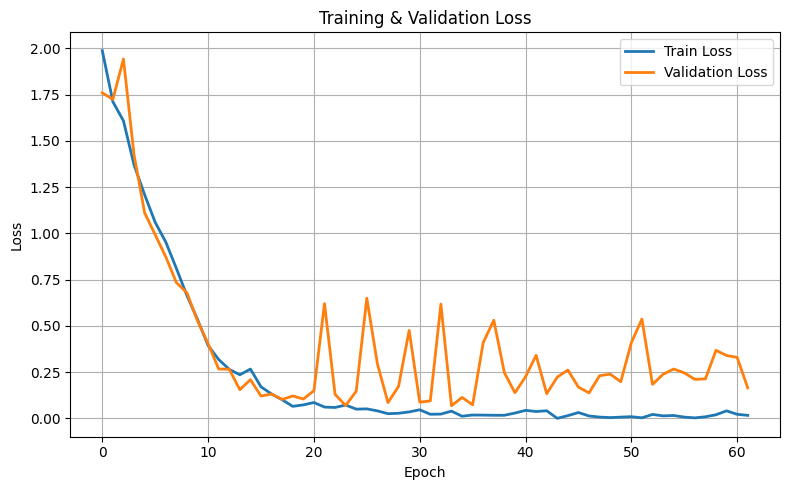

In [42]:
############################################################
# 42. TRAINING LOSS CURVE
############################################################

plt.figure(figsize=(8,5))

plt.plot(
    history["train_loss"],
    label="Train Loss",
    linewidth=2
)

plt.plot(
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training & Validation Loss")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        CONFIG["SAVE_DIR"],
        "loss_curve.png"
    ),
    dpi=300
)

plt.show()

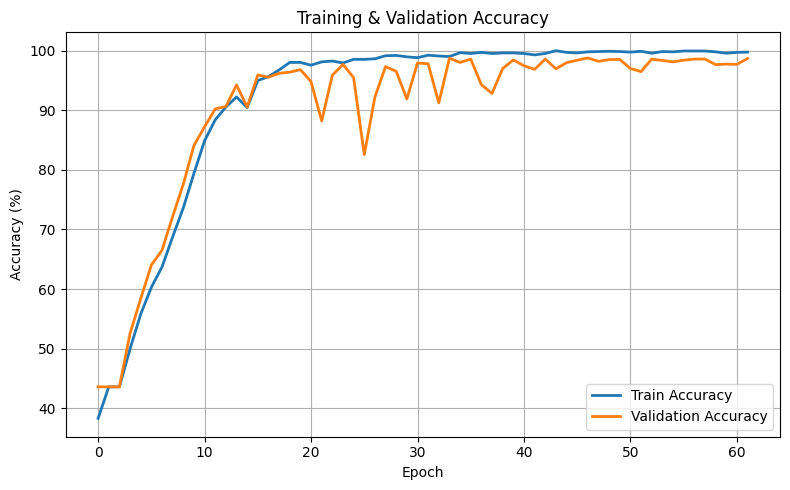

In [43]:
############################################################
# 43. ACCURACY CURVE
############################################################

plt.figure(figsize=(8,5))

plt.plot(
    history["train_acc"],
    label="Train Accuracy",
    linewidth=2
)

plt.plot(
    history["val_acc"],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Training & Validation Accuracy")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        CONFIG["SAVE_DIR"],
        "accuracy_curve.png"
    ),
    dpi=300
)

plt.show()

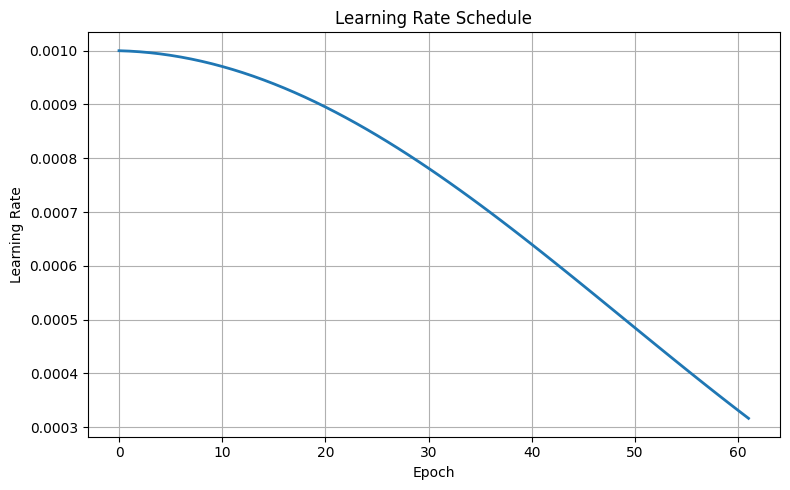

In [44]:
############################################################
# 44. LEARNING RATE CURVE
############################################################

plt.figure(figsize=(8,5))

plt.plot(
    history["lr"],
    linewidth=2
)

plt.xlabel("Epoch")

plt.ylabel("Learning Rate")

plt.title("Learning Rate Schedule")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        CONFIG["SAVE_DIR"],
        "lr_curve.png"
    ),
    dpi=300
)

plt.show()

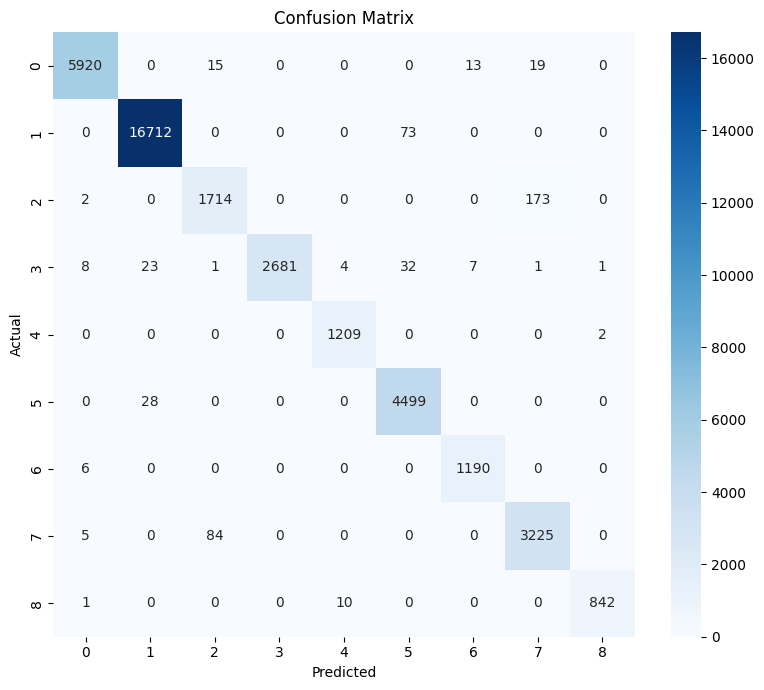

In [45]:
############################################################
# 45. CONFUSION MATRIX
############################################################

plt.figure(figsize=(8,7))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues"

)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.tight_layout()

plt.savefig(

    os.path.join(

        CONFIG["SAVE_DIR"],

        "confusion_matrix.png"

    ),

    dpi=300

)

plt.show()

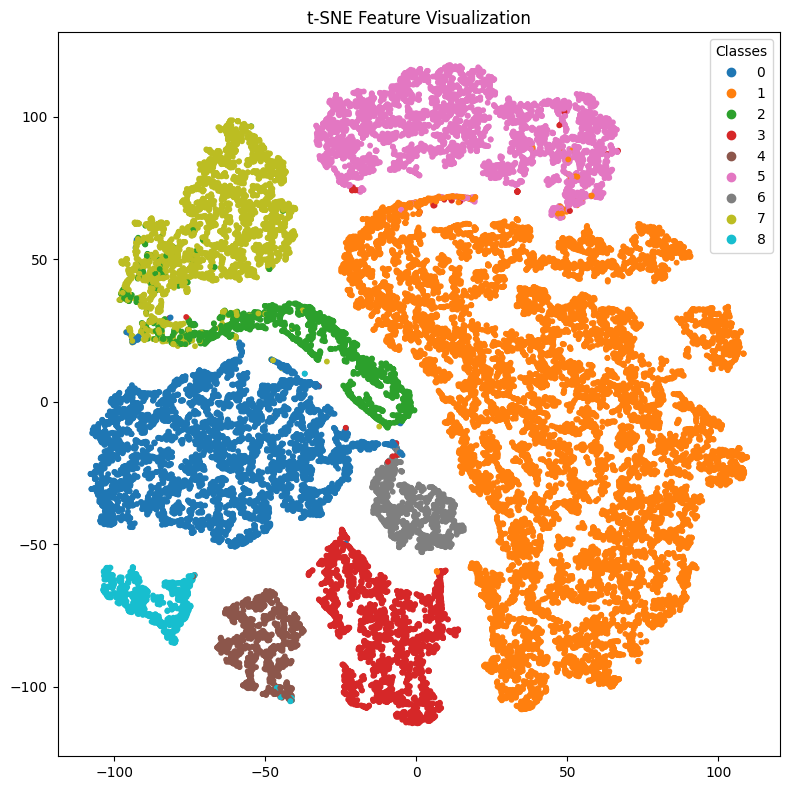

In [46]:
############################################################
# 46. TSNE
############################################################

tsne = TSNE(

    n_components=2,

    random_state=42,

    perplexity=30

)

features_2d = tsne.fit_transform(features)

plt.figure(figsize=(8,8))

scatter = plt.scatter(

    features_2d[:,0],

    features_2d[:,1],

    c=y_true,

    cmap="tab10",

    s=10

)

plt.legend(

    *scatter.legend_elements(),

    title="Classes"

)

plt.title("t-SNE Feature Visualization")

plt.tight_layout()

plt.savefig(

    os.path.join(

        CONFIG["SAVE_DIR"],

        "tsne_features.png"

    ),

    dpi=300

)

plt.show()

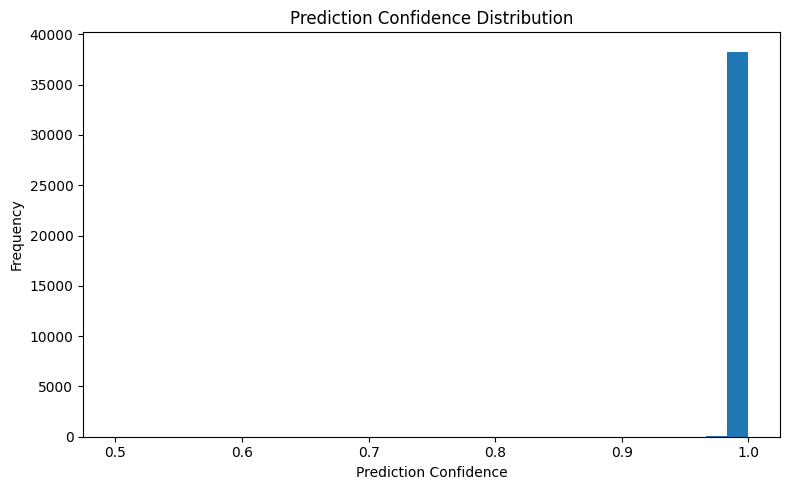

In [47]:
############################################################
# 47. CONFIDENCE HISTOGRAM
############################################################

confidence = np.max(

    y_prob,

    axis=1

)

plt.figure(figsize=(8,5))

plt.hist(

    confidence,

    bins=30

)

plt.xlabel("Prediction Confidence")

plt.ylabel("Frequency")

plt.title("Prediction Confidence Distribution")

plt.tight_layout()

plt.savefig(

    os.path.join(

        CONFIG["SAVE_DIR"],

        "confidence_histogram.png"

    ),

    dpi=300

)

plt.show()

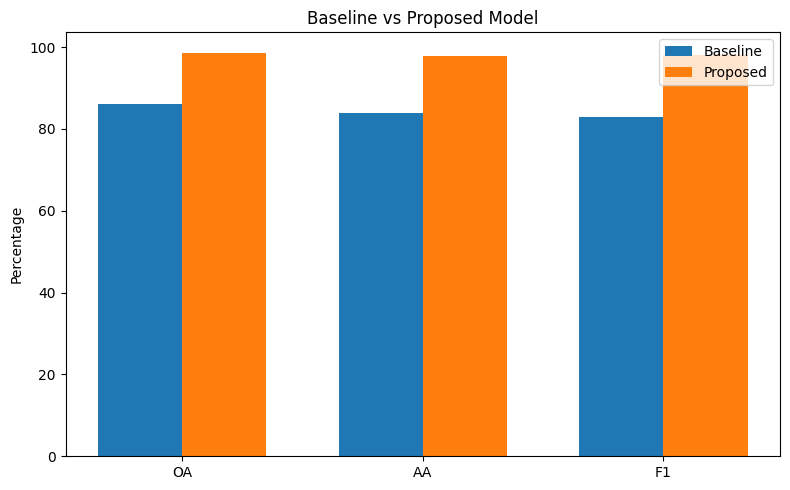

In [48]:
############################################################
# 48. BEFORE VS AFTER
############################################################

baseline_metrics = {

    "OA":86,

    "AA":84,

    "F1":83

}

proposed_metrics = {

    "OA":OA*100,

    "AA":AA*100,

    "F1":f1*100

}

labels = [

    "OA",

    "AA",

    "F1"

]

baseline = [

    baseline_metrics[x]

    for x in labels

]

proposed = [

    proposed_metrics[x]

    for x in labels

]

x = np.arange(len(labels))

width = 0.35

plt.figure(figsize=(8,5))

plt.bar(

    x-width/2,

    baseline,

    width,

    label="Baseline"

)

plt.bar(

    x+width/2,

    proposed,

    width,

    label="Proposed"

)

plt.xticks(x,labels)

plt.ylabel("Percentage")

plt.title("Baseline vs Proposed Model")

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        CONFIG["SAVE_DIR"],

        "before_after_comparison.png"

    ),

    dpi=300

)

plt.show()

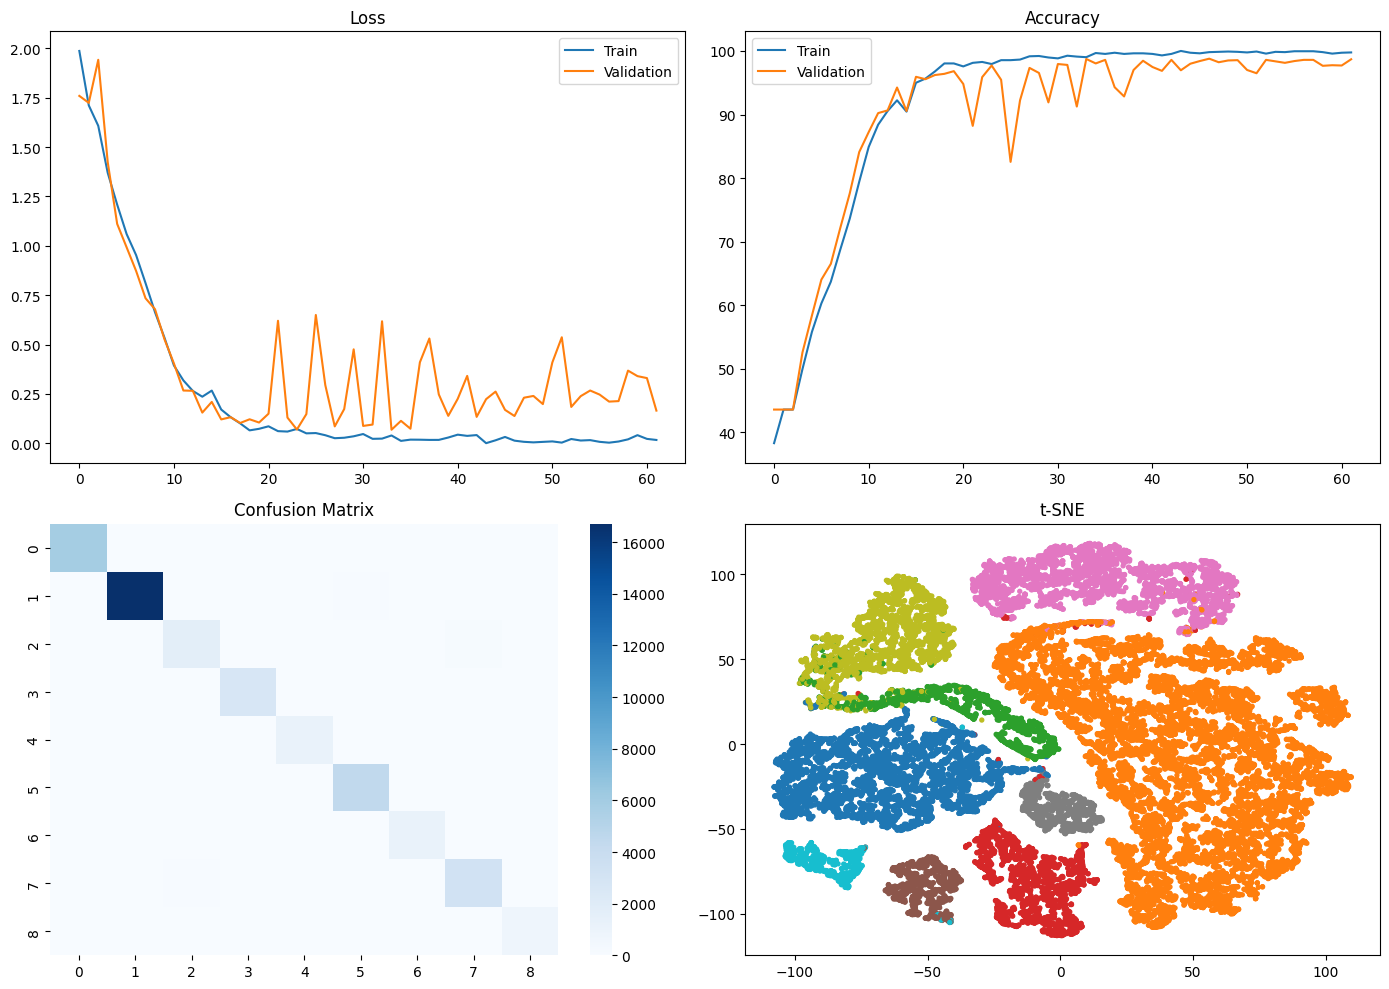

In [49]:
############################################################
# 49. FINAL DASHBOARD
############################################################

fig,axs = plt.subplots(

    2,

    2,

    figsize=(14,10)

)

axs[0,0].plot(history["train_loss"],label="Train")
axs[0,0].plot(history["val_loss"],label="Validation")
axs[0,0].set_title("Loss")
axs[0,0].legend()

axs[0,1].plot(history["train_acc"],label="Train")
axs[0,1].plot(history["val_acc"],label="Validation")
axs[0,1].set_title("Accuracy")
axs[0,1].legend()

sns.heatmap(

    cm,

    ax=axs[1,0],

    cmap="Blues"

)

axs[1,0].set_title("Confusion Matrix")

axs[1,1].scatter(

    features_2d[:,0],

    features_2d[:,1],

    c=y_true,

    s=8,

    cmap="tab10"

)

axs[1,1].set_title("t-SNE")

plt.tight_layout()

plt.savefig(

    os.path.join(

        CONFIG["SAVE_DIR"],

        "dashboard.png"

    ),

    dpi=300

)

plt.show()

In [50]:
############################################################
# 50. OUTPUT SUMMARY
############################################################

print("="*70)

print("Notebook 03 Completed Successfully")

print("="*70)

print("Generated Files:")

for file in sorted(os.listdir(CONFIG["SAVE_DIR"])):

    print(file)

print("="*70)

Notebook 03 Completed Successfully
Generated Files:
accuracy_curve.png
before_after_comparison.png
best_checkpoint.pth
classification_report.txt
confidence_histogram.png
confusion_matrix.png
dashboard.png
loss_curve.png
lr_curve.png
metrics.csv
training_history.csv
training_summary.txt
tsne_features.png


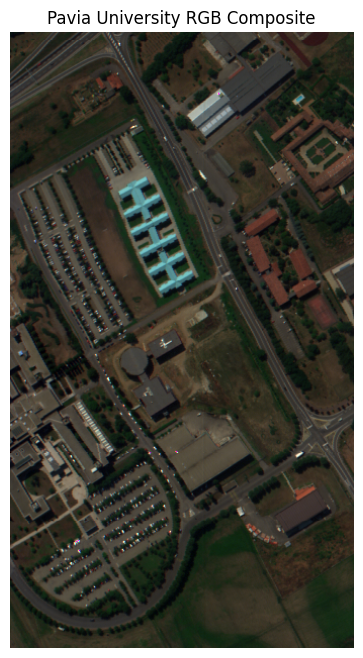

In [58]:
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np

# Update these paths
cube = loadmat("/kaggle/input/datasets/syamkakarla/pavia-university-hsi/PaviaU.mat")["paviaU"]

rgb = cube[:, :, [60, 30, 10]].astype(np.float32)

for i in range(3):
    rgb[:, :, i] = (rgb[:, :, i] - rgb[:, :, i].min()) / (
        rgb[:, :, i].max() - rgb[:, :, i].min() + 1e-8
    )

rgb = np.power(rgb, 0.8)

plt.figure(figsize=(8,8))
plt.imshow(rgb)
plt.axis("off")
plt.title("Pavia University RGB Composite")
plt.show()

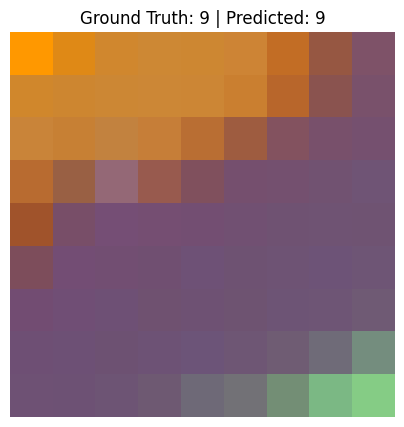

In [59]:
############################################################
# DISPLAY ONE CLASSIFIED PATCH
############################################################

import matplotlib.pyplot as plt
import numpy as np

# Select any test patch
index = 100   # Change to any index from 0 to len(X_test)-1

patch = X_test[index]

# Use first 3 PCA components as RGB visualization
rgb = patch[:, :, :3].astype(np.float32)

# Normalize
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)

# Prediction and Ground Truth
predicted_class = y_pred[index] + 1
actual_class = y_test[index] + 1

plt.figure(figsize=(5,5))
plt.imshow(rgb)
plt.title(
    f"Ground Truth: {actual_class} | Predicted: {predicted_class}",
    fontsize=12
)
plt.axis("off")
plt.show()